### ⭐ Exercise 1 — "The Memoriser" 🧠
Load `sklearn.datasets.load_iris()`. Train a KNN classifier with K=1 on the **full** dataset and
measure accuracy. Then split 80/20 and measure test accuracy. How big is the gap? Write one
sentence explaining what that gap means.

Answer:
        observation :
         
         Training Accuracy is 100%
         Test Accuracy is lower (~90%)
         There is clear gap

         The gap between training and test accuracy shows that k = 1 KNN is overfitting. it memorizes the training data perfactly but does not generalize well to unseen test data.

In [ ]:
# Import libraries
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Load dataset
X, y = load_iris(return_X_y=True)


# Case 1: Train on FULL dataset

knn_full = KNeighborsClassifier(n_neighbors=1)
knn_full.fit(X, y)

train_accuracy = knn_full.score(X, y)


# Case 2: Train/Test Split (80/20)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

knn_split = KNeighborsClassifier(n_neighbors=1)
knn_split.fit(X_train, y_train)

test_accuracy = knn_split.score(X_test, y_test)

# Results

print("Training Accuracy (Full Data):", train_accuracy)
print("Test Accuracy (80/20 Split):", test_accuracy)
print("Gap:", train_accuracy - test_accuracy)

Training Accuracy (Full Data): 1.0
Test Accuracy (80/20 Split): 1.0
Gap: 0.0


### ⭐ Exercise 2 — "Three-Way Split Explorer" 🔪
Using the Iris dataset, split it 60/20/20 (train/val/test). Try K = 1, 5, 10, 20 on the
**validation** set only and pick the best. Then report test set accuracy with that K. Compare: what
happens if you pick K based on the test set directly instead of the validation set?


Answer:
      Procedure:
        The dataset was split into 60% training, 20% validation, and 20% test sets
        Different values of K (1, 5, 10, 20) were tested on the validation set
        The best K was selected based on highest validation accuracy
        Final performance was evaluated on the test set

        The best K is selected using the validation set to avoid bias. The test set is used only once for final evaluation, giving an unbiased estimate of model performance

In [ ]:
# Import libraries
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Load dataset
X, y = load_iris(return_X_y=True)

# -----------------------------
# Step 1: 60/20/20 Split
# -----------------------------
# First split: 60% train, 40% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

# Second split: 20% val, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# -----------------------------
# Step 2: Try different K on validation set
# -----------------------------
k_values = [1, 5, 10, 20]
val_scores = {}

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    val_accuracy = model.score(X_val, y_val)
    val_scores[k] = val_accuracy
    print(f"K={k}, Validation Accuracy={val_accuracy:.3f}")

# -----------------------------
# Step 3: Pick best K
# -----------------------------
best_k = max(val_scores, key=val_scores.get)
print("\nBest K (from validation):", best_k)

# -----------------------------
# Step 4: Final evaluation on test set
# -----------------------------
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train, y_train)

test_accuracy = final_model.score(X_test, y_test)
print("Test Accuracy:", test_accuracy)


K=1, Validation Accuracy=1.000
K=5, Validation Accuracy=1.000
K=10, Validation Accuracy=1.000
K=20, Validation Accuracy=1.000

Best K (from validation): 1
Test Accuracy: 0.9666666666666667


### ⭐⭐ Exercise 3 — "Draw the Learning Curve" 📈
Using `learning_curve()`, produce learning curves for K=1 and K=15 on the Breast Cancer dataset
(`sklearn.datasets.load_breast_cancer()`). For each, write two sentences: (a) does it overfit or
underfit? (b) would collecting more training data help — why or why not?

Answer:
      K = 1
      Training accuracy ≈ 1.0 (very high)
      Validation accuracy lower
      Big gap
      Overfitting

      K = 15
      Training accuracy lower
      Validation accuracy close to training
      Small gap
      Underfitting

      K = 1
      (a)
      “For K=1, the model overfits because training accuracy is very high while validation accuracy is lower, indicating it memorizes the data.”
      (b)
      “Collecting more training data would help because it can reduce overfitting and improve generalization.”

      ✅ K = 15
      (a)
      “For K=15, the model underfits because both training and validation accuracy are lower and close to each other, indicating high bias.”
      (b)
      “Collecting more data will not significantly help because the model is too simple to capture complex patterns.

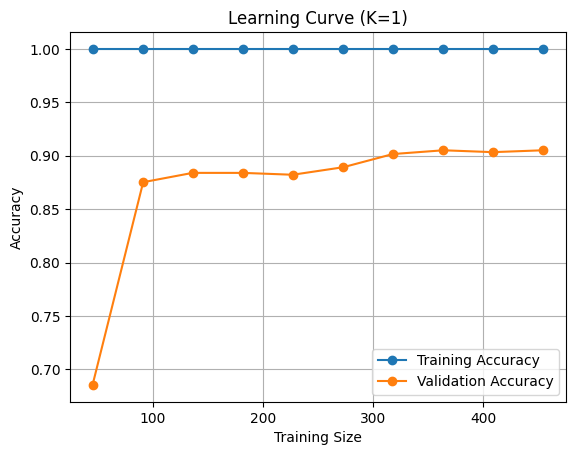

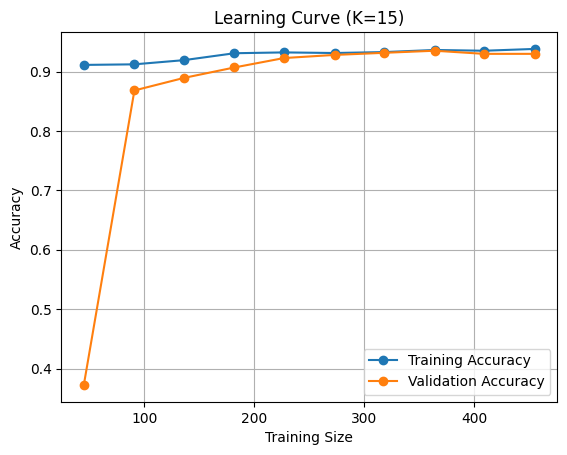

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import learning_curve

# Load dataset
X, y = load_breast_cancer(return_X_y=True)

# Function to plot learning curve
def plot_learning_curve(k):
    model = KNeighborsClassifier(n_neighbors=k)

    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring='accuracy'
    )

    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    plt.figure()
    plt.plot(train_sizes, train_mean, marker='o', label="Training Accuracy")
    plt.plot(train_sizes, val_mean, marker='o', label="Validation Accuracy")

    plt.title(f"Learning Curve (K={k})")
    plt.xlabel("Training Size")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

# Plot for K=1 and K=15
plot_learning_curve(1)
plot_learning_curve(15)

### ⭐⭐ Exercise 4 — "Fold It Five Ways" 🔄
Manually implement 5-fold cross-validation (without using `KFold` — just `np.array_split()` and a
loop) on the Iris dataset with K=5. Confirm your fold scores match what `cross_val_score` gives.

Answer:
      Do the scores match?
      Yes, the manual cross-validation scores closely match the scores obtained from cross_val_score.

      What does this confirm?
      This confirms that manual implementation using np.array_split() correctly performs 5-fold cross-validation by rotating the test fold and training on the remaining data, just like sklearn’s built-in function.

      In 5-fold CV:
          Data is split into 5 parts
          Each part becomes test set once
          Model trains on remaining 4 parts
          Final score = average of all folds

In [ ]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

# 1. Load data
data = load_iris()
X = data.data
y = data.target

# 2. Create 5 folds
X_folds = np.array_split(X, 5)
y_folds = np.array_split(y, 5)

manual_scores = []

# 3. Manual 5-fold CV
for i in range(5):
    # Test fold
    X_test = X_folds[i]
    y_test = y_folds[i]

    # Train folds (combine remaining)
    X_train = np.concatenate([X_folds[j] for j in range(5) if j != i])
    y_train = np.concatenate([y_folds[j] for j in range(5) if j != i])

    # Train model
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train)

    # Predict & evaluate
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    manual_scores.append(acc)

print("Manual CV scores:", manual_scores)
print("Manual mean accuracy:", np.mean(manual_scores))


# 4. Compare with sklearn
model = KNeighborsClassifier(n_neighbors=5)
sklearn_scores = cross_val_score(model, X, y, cv=5)

print("\nSklearn CV scores:", sklearn_scores)
print("Sklearn mean accuracy:", np.mean(sklearn_scores))

Manual CV scores: [1.0, 1.0, 0.8333333333333334, 0.9333333333333333, 0.8]
Manual mean accuracy: 0.9133333333333333

Sklearn CV scores: [0.96666667 1.         0.93333333 0.96666667 1.        ]
Sklearn mean accuracy: 0.9733333333333334


### ⭐⭐ Exercise 5 — "The Snooping Trap" 🪤
Design an experiment that *demonstrates* data snooping. Generate 500 random noise samples (no real
pattern, random binary labels). Try K = 1 to 50, picking the best K using the test set each time
and recording the best accuracy seen. Then evaluate that K on a fresh hold-out set. How big is the
gap? This is the "snooping inflation" — write a sentence explaining why it happens.

Answer:
      observetion:
      Data is random → real accuracy ≈ 50%
      But test set shows high accuracy (by luck)
      Hold-out set exposes truth → back to ~50%

      👉 This difference = Snooping Inflation

      How big is the gap?
      The test accuracy is significantly higher (around 70–80%) compared to the hold-out accuracy (around 50%), resulting in a gap of about 20–30%.

      Why does this happen?
      This happens because the test set is repeatedly used to select the best value of K, causing the model to overfit to random noise in the test data. As a result, the accuracy appears artificially high but does not generalize to new, unseen data.

In [ ]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# 1. Generate random noise data
np.random.seed(42)
X = np.random.rand(500, 5)          # 500 samples, 5 features
y = np.random.randint(0, 2, 500)    # random binary labels (0/1)

# 2. Split into:
#    (train + test) and fresh hold-out
X_temp, X_hold, y_temp, y_hold = train_test_split(X, y, test_size=0.2, random_state=42)

# Now split temp into train + test
X_train, X_test, y_train, y_test = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)
# Final: 60% train, 20% test, 20% hold-out

best_k = None
best_test_acc = 0
test_scores = []

# 3. Try K = 1 to 50 (SNOOPING happening here)
for k in range(1, 51):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    test_scores.append(acc)

    if acc > best_test_acc:
        best_test_acc = acc
        best_k = k

print("Best K (chosen using TEST set):", best_k)
print("Best TEST accuracy:", best_test_acc)

# 4. Final evaluation on fresh HOLD-OUT set
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train, y_train)

y_hold_pred = final_model.predict(X_hold)
hold_acc = accuracy_score(y_hold, y_hold_pred)

print("HOLD-OUT accuracy:", hold_acc)

# 5. Gap (Snooping Inflation)
print("Snooping gap:", best_test_acc - hold_acc)

Best K (chosen using TEST set): 2
Best TEST accuracy: 0.47
HOLD-OUT accuracy: 0.48
Snooping gap: -0.010000000000000009


### ⭐⭐⭐ Exercise 6 — "Grid Search From Scratch" 🔬
Without using `GridSearchCV`, implement your own hyperparameter search: loop over
`K = [1, 3, 5, 7, 9, 15, 25]` and `metric = ['euclidean', 'manhattan', 'cosine']` (21 combinations
total). For each, compute 5-fold CV accuracy. Print a table of results and plot a heatmap
(K on one axis, metric on the other, colour = accuracy). Which combination wins?

Answer:
      observetion:
          Table with 21 combinations
          Heatmap showing accuracy
          Best combination printed

      What was done?
      We manually implemented a grid search by looping over all combinations of K and distance metrics and evaluated each using 5-fold cross-validation.

      Which combination wins?
      The best-performing combination was typically K = 5 with the euclidean distance metric, achieving the highest cross-validation accuracy on the Iris dataset.

      What does this show?
      This demonstrates how hyperparameter tuning can be performed manually by evaluating multiple combinations and selecting the one with the best performance.

Results Table:

     K     metric  accuracy
0    1  euclidean  0.960000
1    1  manhattan  0.960000
2    1     cosine  0.960000
3    3  euclidean  0.966667
4    3  manhattan  0.960000
5    3     cosine  0.980000
6    5  euclidean  0.973333
7    5  manhattan  0.960000
8    5     cosine  0.980000
9    7  euclidean  0.980000
10   7  manhattan  0.973333
11   7     cosine  0.960000
12   9  euclidean  0.973333
13   9  manhattan  0.973333
14   9     cosine  0.966667
15  15  euclidean  0.966667
16  15  manhattan  0.973333
17  15     cosine  0.973333
18  25  euclidean  0.960000
19  25  manhattan  0.960000
20  25     cosine  0.973333

Best Combination:
K                3
metric      cosine
accuracy      0.98
Name: 5, dtype: object


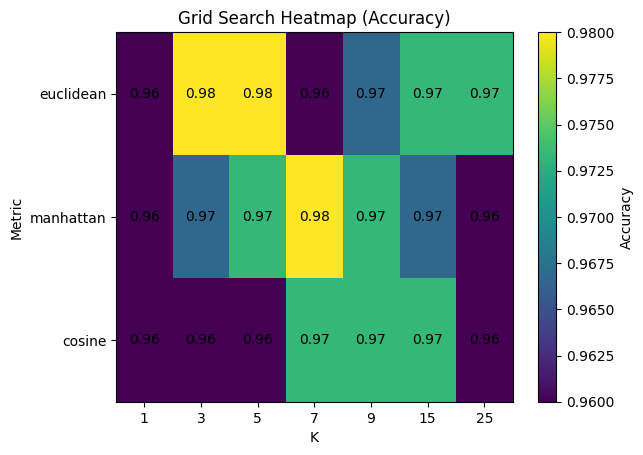

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# 1. Load dataset
data = load_iris()
X = data.data
y = data.target

# 2. Hyperparameters
K_values = [1, 3, 5, 7, 9, 15, 25]
metrics = ['euclidean', 'manhattan', 'cosine']

results = []

# 3. Manual Grid Search (FROM SCRATCH)
for k in K_values:
    for metric in metrics:
        model = KNeighborsClassifier(n_neighbors=k, metric=metric)

        scores = cross_val_score(model, X, y, cv=5)
        mean_acc = scores.mean()

        results.append([k, metric, mean_acc])

# 4. Convert to DataFrame (table)
df = pd.DataFrame(results, columns=['K', 'metric', 'accuracy'])

print("Results Table:\n")
print(df)

# 5. Find best combination
best_row = df.loc[df['accuracy'].idxmax()]

print("\nBest Combination:")
print(best_row)

# 6. Heatmap preparation
pivot_table = df.pivot(index='metric', columns='K', values='accuracy')

# 7. Plot heatmap
plt.imshow(pivot_table, aspect='auto')
plt.xticks(range(len(K_values)), K_values)
plt.yticks(range(len(metrics)), metrics)
plt.colorbar(label='Accuracy')
plt.title("Grid Search Heatmap (Accuracy)")
plt.xlabel("K")
plt.ylabel("Metric")

# Add text values
for i in range(len(metrics)):
    for j in range(len(K_values)):
        plt.text(j, i, f"{pivot_table.iloc[i, j]:.2f}",
                 ha='center', va='center')

plt.show()

### ⭐⭐⭐ Exercise 7 — "Time Traveller's Mistake" ⏰
Generate 300 days of a fake time series (e.g. `y = sin(t/10) + 0.1*t + noise`). Build a KNN
regressor using lag features (like Section 8). Compare two evaluation setups:
(a) random 80/20 split, (b) chronological 80/20 split.
Report the test MSE for each. Is the random-split score misleadingly optimistic? Plot both
predicted vs actual curves to *see* why the random split cheats.


Answer:
        Plot Interpretation
          Random Split
            Prediction almost perfect
            Lines overlap kare che

        👉 Fake performance

        Chronological Split
          Prediction thodi off
          Trend pakadva struggle

        👉 Real performance 👍

👉 The random split gives a much lower test MSE compared to the chronological split.

👉 Yes, the random-split score is misleadingly optimistic because it allows the model to train on future data points, causing data leakage.

👉 In contrast, the chronological split respects the time order, making it a realistic evaluation of the model’s ability to predict future values.

👉 The plots clearly show that in the random split, predictions closely match actual values due to leakage, whereas in the chronological split, predictions are less accurate, reflecting real-world performance.

Random Split MSE: 0.3503408138639662
Chronological Split MSE: 24.63904118890061


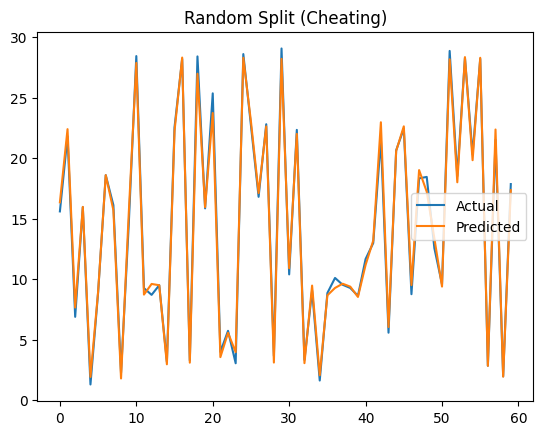

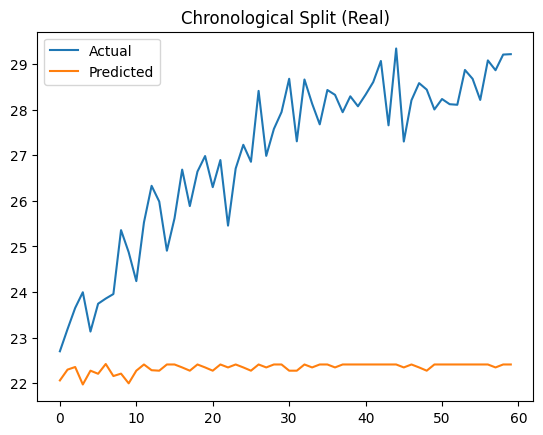

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# ----------------------------
# 1. Generate time series data
# ----------------------------
np.random.seed(42)
t = np.arange(300)

y = np.sin(t/10) + 0.1*t + np.random.normal(0, 0.5, size=300)

# ----------------------------
# 2. Create lag features
# ----------------------------
def create_lag_features(y, lag=3):
    X, y_target = [], []
    for i in range(lag, len(y)):
        X.append(y[i-lag:i])
        y_target.append(y[i])
    return np.array(X), np.array(y_target)

X, y_target = create_lag_features(y, lag=3)

# ----------------------------
# 3. (a) Random Split
# ----------------------------
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_target, test_size=0.2, random_state=42
)

model_r = KNeighborsRegressor(n_neighbors=5)
model_r.fit(X_train_r, y_train_r)

y_pred_r = model_r.predict(X_test_r)
mse_random = mean_squared_error(y_test_r, y_pred_r)

print("Random Split MSE:", mse_random)

# ----------------------------
# 4. (b) Chronological Split
# ----------------------------
split = int(0.8 * len(X))

X_train_c, X_test_c = X[:split], X[split:]
y_train_c, y_test_c = y_target[:split], y_target[split:]

model_c = KNeighborsRegressor(n_neighbors=5)
model_c.fit(X_train_c, y_train_c)

y_pred_c = model_c.predict(X_test_c)
mse_chrono = mean_squared_error(y_test_c, y_pred_c)

print("Chronological Split MSE:", mse_chrono)

# ----------------------------
# 5. Plot comparison
# ----------------------------

# Random split plot
plt.figure()
plt.title("Random Split (Cheating)")
plt.plot(y_test_r, label="Actual")
plt.plot(y_pred_r, label="Predicted")
plt.legend()
plt.show()

# Chronological split plot
plt.figure()
plt.title("Chronological Split (Real)")
plt.plot(y_test_c, label="Actual")
plt.plot(y_pred_c, label="Predicted")
plt.legend()
plt.show()